In [ ]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.data.RadialDevice import RadialDevice
from src.viz.CellVisualizer import CellVisualizer
import numpy as np
import matplotlib.pyplot as plt
import pickle

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM041'
record_date = '251128'
experiment_name = 'tiling_3_120um'

data_dir = os.path.join(data_dir, f'{record_date}_{mouse_name}_{experiment_name}')
R = RadialDevice(mouse_name=mouse_name, record_date = record_date, experiment_name = experiment_name)
viz = CellVisualizer(R)

df_name = f'{record_date}_{mouse_name}_{experiment_name}_dataframe.pkl'
df_path = os.path.join(data_dir, df_name)

try:
    with open(df_path, 'rb') as f:
        session_df = pickle.load(f)
        print(f"File {df_name} imported.")
except FileNotFoundError:
    print(f"The file {df_name} does not exist.")
    print(f"Computing dataframe...")
    session_df = R.analyze_session_stats()
    with open(df_path, 'wb') as f:
        pickle.dump(session_df, f)

In [3]:
def identify_cells(session_stats, threshold):

    reliable = session_stats[
        (session_stats['monocular'].apply(lambda x: x['reliable']) == True) &
        (session_stats['binocular'].apply(lambda x: x['reliable']) == True) &
        ((session_stats['monocular'].apply(lambda x: x['reliable_corr']) >= threshold) |
        (session_stats['binocular'].apply(lambda x: x['reliable_corr']) >= threshold))
    ]['cell_id'].values

    # Filter for cells that are in the reliable set AND meet the monocular/binocular criteria
    monocular_only = session_stats[
        (session_stats['cell_id'].isin(reliable)) &
        (session_stats['monocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05) &
        (session_stats['binocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05)
    ]['cell_id'].values

    binocular_only = session_stats[
        (session_stats['cell_id'].isin(reliable)) &
        (session_stats['monocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05) &
        (session_stats['binocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05)
    ]['cell_id'].values

    both = session_stats[
        (session_stats['cell_id'].isin(reliable)) &
        (session_stats['monocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05) &
        (session_stats['binocular'].apply(lambda x: x['bootstrap_pvalue']) < 0.05)
    ]['cell_id'].values

    none = session_stats[
        (session_stats['cell_id'].isin(reliable)) &
        (session_stats['monocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05) &
        (session_stats['binocular'].apply(lambda x: x['bootstrap_pvalue']) > 0.05)
    ]['cell_id'].values

    return reliable, monocular_only, binocular_only, both, none

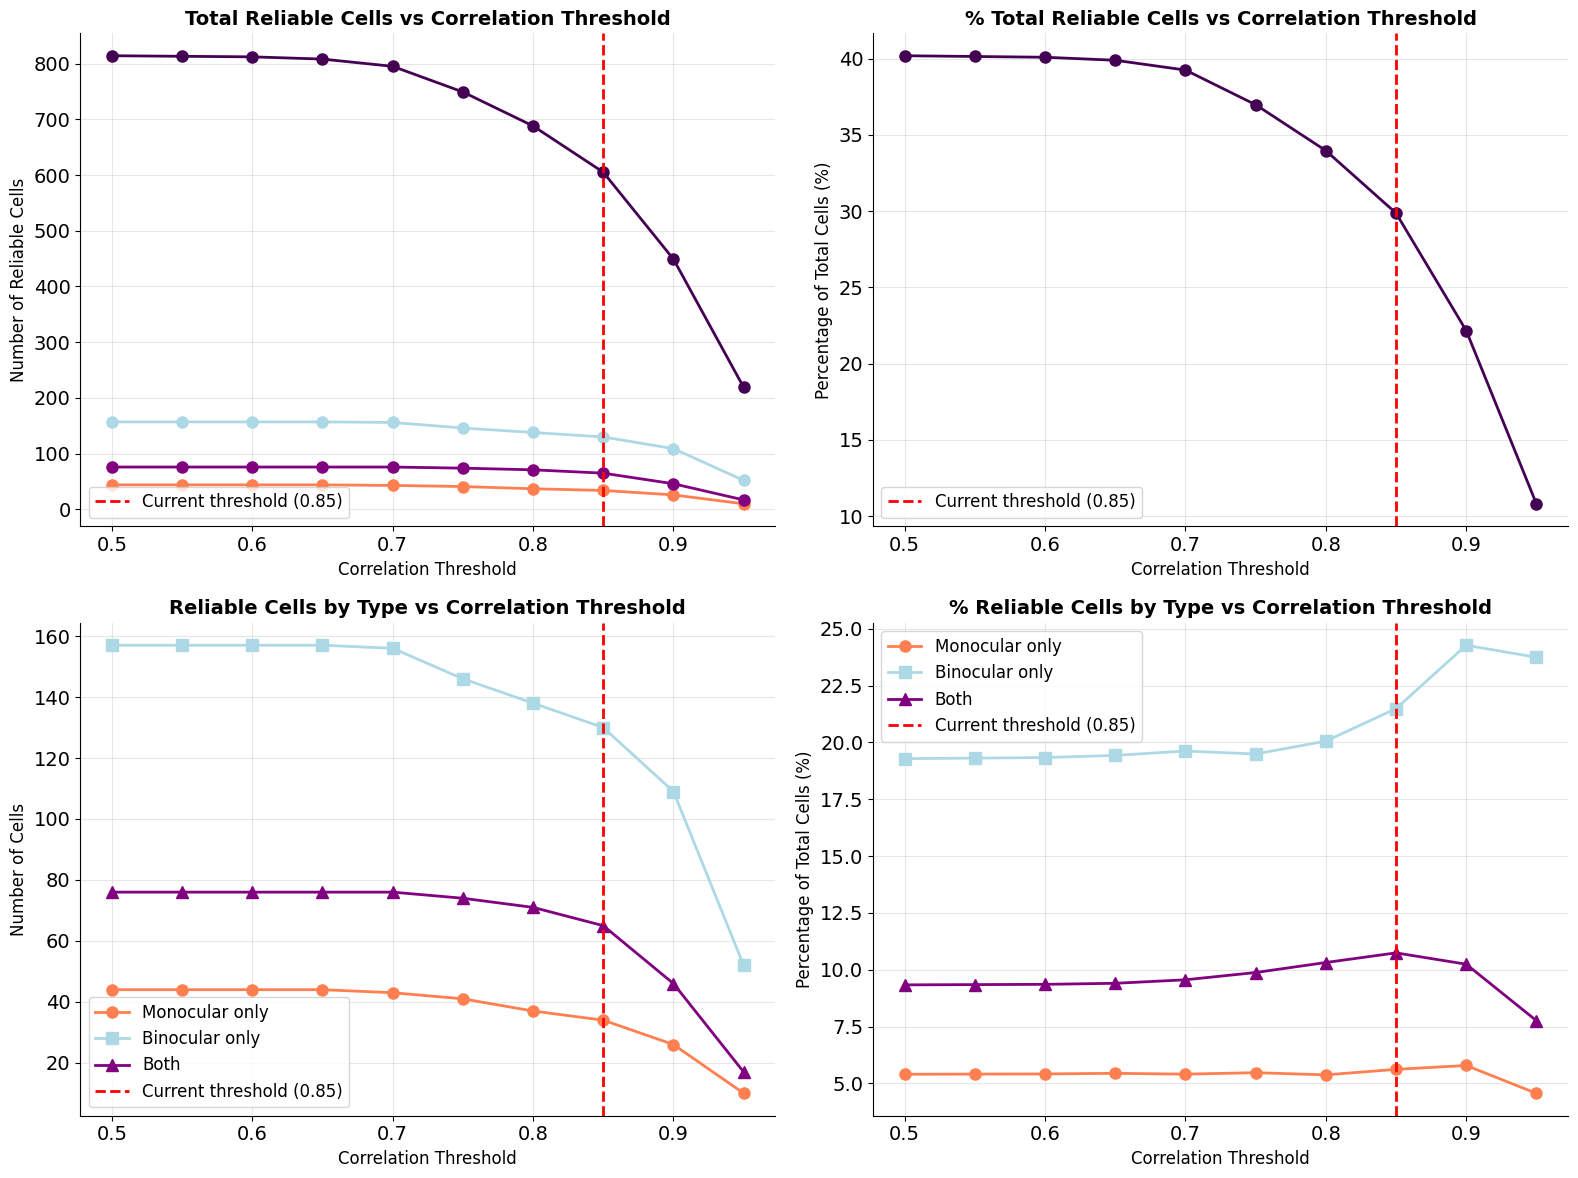


 threshold  n_reliable_cells  n_monocular_only  n_binocular_only  n_both  percentage  percentage_monocular_only  percentage_binocular_only  percentage_both
      0.50               814                44               157      76   40.197531                   5.405405                  19.287469         9.336609
      0.55               813                44               157      76   40.148148                   5.412054                  19.311193         9.348093
      0.60               812                44               157      76   40.098765                   5.418719                  19.334975         9.359606
      0.65               808                44               157      76   39.901235                   5.445545                  19.430693         9.405941
      0.70               795                43               156      76   39.259259                   5.408805                  19.622642         9.559748
      0.75               749                41               14

In [5]:
# Test different correlation thresholds to see how many cells are reliable
import pandas as pd

# Define range of correlation thresholds to test
corr_thresholds = np.arange(0.5, 1.0, 0.05)

# Store results
threshold_results = {
    'threshold': [],
    'n_reliable_cells': [],
    'n_monocular_only': [],
    'n_binocular_only': [],
    'n_both': [],
}

# Get total number of cells
total_cells = len(session_df)

for threshold in corr_thresholds:
    
    reliable, monocular_only, binocular_only, both, none = identify_cells(session_df, threshold)

    threshold_results['threshold'].append(threshold)
    threshold_results['n_reliable_cells'].append(len(reliable))
    threshold_results['n_monocular_only'].append(len(monocular_only))
    threshold_results['n_binocular_only'].append(len(binocular_only))
    threshold_results['n_both'].append(len(both))
    
    
# Create DataFrame
threshold_df = pd.DataFrame(threshold_results)
threshold_df['percentage'] = (threshold_df['n_reliable_cells'] / total_cells) * 100
threshold_df['percentage_monocular_only'] = (threshold_df['n_monocular_only'] / threshold_df['n_reliable_cells']) * 100
threshold_df['percentage_binocular_only'] = (threshold_df['n_binocular_only'] / threshold_df['n_reliable_cells']) * 100
threshold_df['percentage_both'] = (threshold_df['n_both'] / threshold_df['n_reliable_cells']) * 100

# Plot the results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Total number of reliable cells vs threshold
ax1 = axes[0, 0]
ax1.plot(threshold_df['threshold'], threshold_df['n_reliable_cells'], 
         marker='o', linewidth=2, markersize=8, color='#440154')
ax1.plot(threshold_df['threshold'], threshold_df['n_monocular_only'], 
         marker='o', linewidth=2, markersize=8, color='coral')
ax1.plot(threshold_df['threshold'], threshold_df['n_binocular_only'], 
         marker='o', linewidth=2, markersize=8, color='lightblue')
ax1.plot(threshold_df['threshold'], threshold_df['n_both'], 
         marker='o', linewidth=2, markersize=8, color='purple')
ax1.axvline(0.85, color='red', linestyle='--', linewidth=2, label='Current threshold (0.85)')
ax1.set_xlabel('Correlation Threshold', fontsize=12)
ax1.set_ylabel('Number of Reliable Cells', fontsize=12)
ax1.set_title('Total Reliable Cells vs Correlation Threshold', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3)
ax1.legend()
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Plot 2: Total percentage vs threshold
ax2 = axes[0, 1]
ax2.plot(threshold_df['threshold'], threshold_df['percentage'], 
         marker='o', linewidth=2, markersize=8, color='#440154')
ax2.axvline(0.85, color='red', linestyle='--', linewidth=2, label='Current threshold (0.85)')
ax2.set_xlabel('Correlation Threshold', fontsize=12)
ax2.set_ylabel('Percentage of Total Cells (%)', fontsize=12)
ax2.set_title('% Total Reliable Cells vs Correlation Threshold', fontsize=14, fontweight='bold')
ax2.grid(alpha=0.3)
ax2.legend()
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Plot 3: Number by type
ax3 = axes[1, 0]
ax3.plot(threshold_df['threshold'], threshold_df['n_monocular_only'], 
         marker='o', linewidth=2, markersize=8, color='coral', label='Monocular only')
ax3.plot(threshold_df['threshold'], threshold_df['n_binocular_only'], 
         marker='s', linewidth=2, markersize=8, color='lightblue', label='Binocular only')
ax3.plot(threshold_df['threshold'], threshold_df['n_both'], 
         marker='^', linewidth=2, markersize=8, color='purple', label='Both')
ax3.axvline(0.85, color='red', linestyle='--', linewidth=2, label='Current threshold (0.85)')
ax3.set_xlabel('Correlation Threshold', fontsize=12)
ax3.set_ylabel('Number of Cells', fontsize=12)
ax3.set_title('Reliable Cells by Type vs Correlation Threshold', fontsize=14, fontweight='bold')
ax3.grid(alpha=0.3)
ax3.legend()
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# Plot 4: Percentage by type
ax4 = axes[1, 1]
ax4.plot(threshold_df['threshold'], threshold_df['percentage_monocular_only'], 
         marker='o', linewidth=2, markersize=8, color='coral', label='Monocular only')
ax4.plot(threshold_df['threshold'], threshold_df['percentage_binocular_only'], 
         marker='s', linewidth=2, markersize=8, color='lightblue', label='Binocular only')
ax4.plot(threshold_df['threshold'], threshold_df['percentage_both'], 
         marker='^', linewidth=2, markersize=8, color='purple', label='Both')
ax4.axvline(0.85, color='red', linestyle='--', linewidth=2, label='Current threshold (0.85)')
ax4.set_xlabel('Correlation Threshold', fontsize=12)
ax4.set_ylabel('Percentage of Total Cells (%)', fontsize=12)
ax4.set_title('% Reliable Cells by Type vs Correlation Threshold', fontsize=14, fontweight='bold')
ax4.grid(alpha=0.3)
ax4.legend()
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Show the DataFrame
print("\n" + "="*80)
print(threshold_df.to_string(index=False))
print("="*80)

In [ ]:
reliable = identify_cells(session_df, 0.85)[0]

window_sizes = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

window_results = {}

for window_size in window_sizes:

    print(f"Window size: {window_size}")

    monocular_modulated = []
    binocular_modulated = []
    both_modulated = []

    for cell in reliable:

        monocular_results = R.bootstrap_modulation(cell = cell, monocular = True, window_size = window_size)
        binocular_results = R.bootstrap_modulation(cell = cell, monocular = False, window_size = window_size)

        monocular_modulated.append((monocular_results['bootstrap_p_value'] < 0.05) 
                                & (binocular_results['bootstrap_p_value'] > 0.05))
        binocular_modulated.append((monocular_results['bootstrap_p_value'] > 0.05) 
                                & (binocular_results['bootstrap_p_value'] < 0.05))
        both_modulated.append((monocular_results['bootstrap_p_value'] < 0.05) 
                                & (binocular_results['bootstrap_p_value'] < 0.05))

    window_results[window_size] = {
        'monocular_modulated': sum(monocular_modulated).tolist(),
        'binocular_modulated': sum(binocular_modulated).tolist(),
        'both_modulated': sum(both_modulated).tolist()
    }

In [ ]:
# Plot window_results
fig, ax = plt.subplots(figsize=(12, 6))

window_sizes_list = list(window_results.keys())
monocular_counts = [window_results[w]['monocular_modulated'] for w in window_sizes_list]
binocular_counts = [window_results[w]['binocular_modulated'] for w in window_sizes_list]
both_counts = [window_results[w]['both_modulated'] for w in window_sizes_list]

# Calculate total reliable cells for percentage
total_reliable = len(reliable)

# Create twin axis for percentage
ax2 = ax.twinx()

# Plot on left axis (counts)
ax.plot(window_sizes_list, monocular_counts, marker='o', label='Monocular only', linewidth=2)
ax.plot(window_sizes_list, binocular_counts, marker='s', label='Binocular only', linewidth=2)
ax.plot(window_sizes_list, both_counts, marker='^', label='Both modulated', linewidth=2)

ax.set_xlabel('Window Size (frames)')
ax.set_ylabel('Number of Modulated Cells')
ax.set_title('Effect of Window Size on Distance Modulation Detection')
ax.legend()
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)

# Set up right axis for percentage
ax2.set_ylabel('Percentage of Reliable Cells (%)')
ax2.set_ylim(0, ax.get_ylim()[1] / total_reliable * 100)
ax2.spines['top'].set_visible(False)

plt.tight_layout()
plt.show()